In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.datasets import FashionMNIST
import torchvision.transforms.v2 as v2

In [2]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

full_train_dataset = FashionMNIST(
    root="./data",
    train=True,
    transform=transform,
    download=True
)
test_dataset = FashionMNIST(
    root="./data",
    train=False,
    transform=transform,
    download=True
)
train_dataset, val_dataset = torch.utils.data.dataset.random_split(full_train_dataset, [len(full_train_dataset)-len(test_dataset), len(test_dataset)])

In [3]:
print(f"{len(train_dataset) = }")
print(f"{len(val_dataset) = }")
print(f"{len(test_dataset) = }")

len(train_dataset) = 50000
len(val_dataset) = 10000
len(test_dataset) = 10000


In [4]:
def build_dataloader(dataset, batch_size):
    return torch.utils.data.DataLoader(
        dataset=dataset,
        batch_size=batch_size,
        shuffle=True
    )

In [5]:
class_to_idx = full_train_dataset.class_to_idx
idx_to_class = {id: cls for cls, id in class_to_idx.items()}

In [6]:
train_dataloader = build_dataloader(train_dataset, batch_size=32)
val_dataloader = build_dataloader(val_dataset, batch_size=32)
test_dataloader = build_dataloader(test_dataset, batch_size=32)

# creating a validation dataloader where batch_size is the length of val_dataset
total_val_dataloader = build_dataloader(val_dataset, batch_size=len(val_dataset))

In [7]:
print(f"{len(train_dataloader) = }")
print(f"{len(val_dataloader) = }")
print(f"{len(test_dataloader) = }")

len(train_dataloader) = 1563
len(val_dataloader) = 313
len(test_dataloader) = 313


In [8]:
batch = next(iter(train_dataloader))

In [9]:
batch[0].shape

torch.Size([32, 1, 28, 28])

In [10]:
batch[1]

tensor([5, 5, 5, 2, 6, 9, 6, 8, 2, 2, 8, 6, 4, 3, 3, 6, 3, 1, 8, 6, 8, 3, 7, 0,
        1, 7, 8, 3, 0, 3, 0, 3])

In [11]:
#=============================================================================

In [12]:
# hyper parameters
max_epoches = 5
lr = 0.1

In [13]:
# just a linear layer
class LinearModel(nn.Module):

    def __init__(self, num_inputs, num_outputs):
        super().__init__()
        self.num_inputs = num_inputs
        self.num_outputs = num_outputs
        self.net = nn.Linear(self.num_inputs, self.num_outputs)

    def forward(self, x):
        return self.net(x.reshape(x.shape[0], -1))

    def loss(self, y_hat, y):
        return F.cross_entropy(y_hat, y)

    def step(self, batch):
        return self.loss(self(batch[0]), batch[1])

In [14]:
model = LinearModel(28*28, len(class_to_idx))
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

In [15]:
losses = torch.empty(size=(max_epoches, len(train_dataloader)))

for epoch in range(max_epoches):
    for i, batch in enumerate(train_dataloader):
        loss = model.step(batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
        # keeping stats
        losses[epoch, i] = loss.item()
    
    print(f"epoch {epoch}: {losses[epoch].mean():.2f}")

epoch 0: 0.60
epoch 1: 0.49
epoch 2: 0.47
epoch 3: 0.46
epoch 4: 0.45


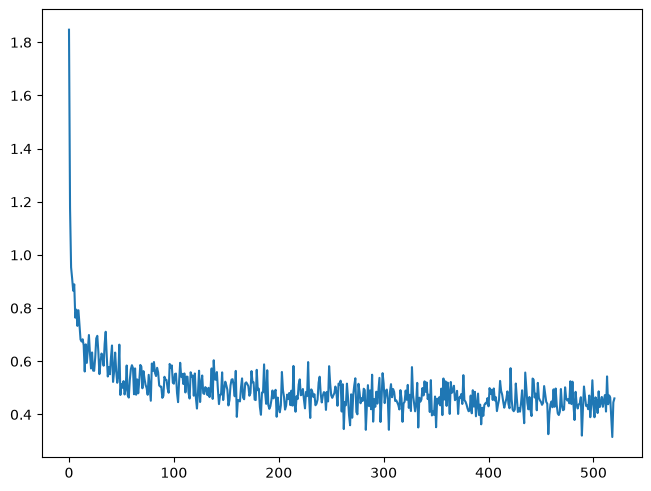

In [16]:
# draw the plot of loss
new_losses = losses.reshape(-1, 15).mean(dim=1)
fig, ax = plt.subplots(layout="constrained")
ax.plot(new_losses.numpy())
plt.show()

In [17]:
# checking the accuracy
with torch.inference_mode():
    for batch in val_dataloader:
        x, y = batch
        logits = model(x)
        logits = logits - logits.max(dim=1, keepdim=True).values
        probs = logits.exp() / logits.exp().sum(dim=1, keepdim=True)
        # accuracy with max
        y_hat1 = probs.max(dim=1).indices
        ncorrect1 = (y_hat1 == y).float()
        accuracy1 = ncorrect1.sum() / len(ncorrect1)
        # accuracy with multinomial
        y_hat2 = torch.multinomial(probs, num_samples=1).squeeze()
        ncorrect2 = (y_hat2 == y).float()
        accuracy2 = ncorrect2.sum() / len(ncorrect2)

        print(f"accuracy with max: {accuracy1:.2f}, accuracy with multinomial: {accuracy2:.2f}")
        break

accuracy with max: 0.94, accuracy with multinomial: 0.84


In [18]:
with torch.inference_mode():
    x, y = next(iter(total_val_dataloader))
    logits = model(x)
    logits = logits - logits.max(dim=1, keepdim=True).values
    probs = logits.exp() / logits.exp().sum(dim=1, keepdim=True)
    # accuracy with max
    y_hat1 = probs.max(dim=1).indices
    ncorrect1 = (y_hat1 == y).float()
    accuracy1 = ncorrect1.sum() / len(ncorrect1)
    # accuracy with multinomial
    y_hat2 = torch.multinomial(probs, num_samples=1).squeeze()
    ncorrect2 = (y_hat2 == y).float()
    accuracy2 = ncorrect2.sum() / len(ncorrect2)

    print(f"accuracy with max: {accuracy1:.2f}, accuracy with multinomial: {accuracy2:.2f}")

accuracy with max: 0.84, accuracy with multinomial: 0.78


In [19]:
# visuilize the incorrect predictions
def visuilize_incorrect_predictions():
    with torch.inference_mode():
        x, y = next(iter(val_dataloader))
        logits = model(x)
        logits = logits - logits.max(dim=1, keepdim=True).values
        probs = logits.exp() / logits.exp().sum(dim=1, keepdim=True)
        y_pred = probs.max(dim=1).indices
    
    incorrects = y_pred != y
    incorrect_indices, = incorrects.nonzero(as_tuple=True)
    incorrect_y_preds = y_pred[incorrects]
    corresponding_correct_preds = y[incorrects]
    
    fig, axs = plt.subplots(ncols=len(incorrect_indices), figsize=(15, 3), layout="constrained")
    for i in range(len(incorrect_indices)):
        img, correct_label, pred_label = x[incorrect_indices[i]].squeeze(0), corresponding_correct_preds[i].item(), incorrect_y_preds[i].item()
        correct_class, pred_class = idx_to_class[correct_label], idx_to_class[pred_label]
    
        axs[i].imshow(img.numpy(), cmap="gray")
        axs[i].axis("off")
        axs[i].set_title(f"act: {correct_class}\npred: {pred_class}")
    plt.show()

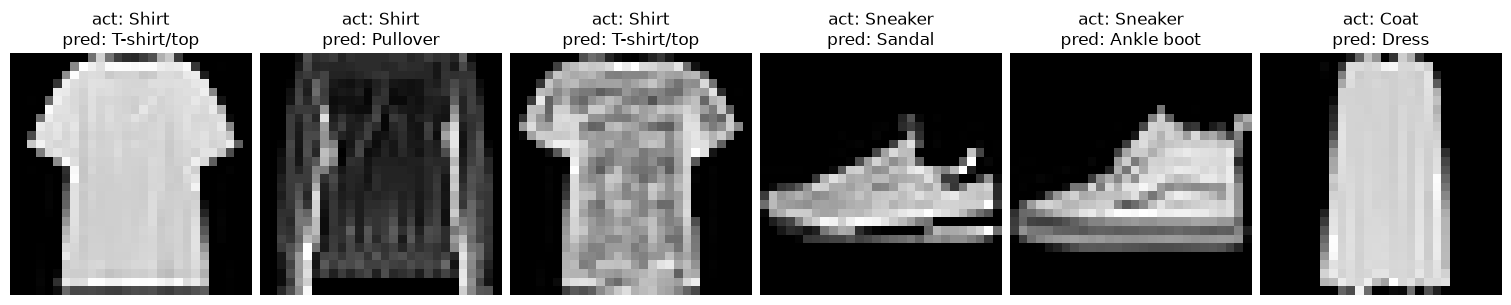

In [20]:
visuilize_incorrect_predictions()